In [2]:
!pip install ucimlrepo

In [3]:
from ucimlrepo import fetch_ucirepo

# Fetch Vertebral Column dataset
vertebral_column = fetch_ucirepo(id=212)

# Separate features and target
X = vertebral_column.data.features
y = vertebral_column.data.targets

# Display dataset information
print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   pelvic_incidence  pelvic_tilt  lumbar_lordosis_angle  sacral_slope  \
0         63.027817    22.552586              39.609117     40.475232   
1         39.056951    10.060991              25.015378     28.995960   
2         68.832021    22.218482              50.092194     46.613539   
3         69.297008    24.652878              44.311238     44.644130   
4         49.712859     9.652075              28.317406     40.060784   

   pelvic_radius  degree_spondylolisthesis  
0      98.672917                 -0.254400  
1     114.405425                  4.564259  
2     105.985135                 -3.530317  
3     101.868495                 11.211523  
4     108.168725                  7.918501  

Target:
    class
0  Hernia
1  Hernia
2  Hernia
3  Hernia
4  Hernia


In [4]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

print("\nFeature names:")
print(X.columns)

print("\nTarget:")
print(y.head())

print("\nTarget classes:")
print(y.iloc[:, 0].unique())

Shape of X: (310, 6)
Shape of y: (310, 1)

Feature names:
Index(['pelvic_incidence', 'pelvic_tilt', 'lumbar_lordosis_angle',
       'sacral_slope', 'pelvic_radius', 'degree_spondylolisthesis'],
      dtype='object')

Target:
    class
0  Hernia
1  Hernia
2  Hernia
3  Hernia
4  Hernia

Target classes:
['Hernia' 'Spondylolisthesis' 'Normal']


In [5]:
import pandas as pd
import numpy as np

df = pd.concat([X, y], axis=1)

print(df.head())
print("\nShape:", df.shape)

   pelvic_incidence  pelvic_tilt  lumbar_lordosis_angle  sacral_slope  \
0         63.027817    22.552586              39.609117     40.475232   
1         39.056951    10.060991              25.015378     28.995960   
2         68.832021    22.218482              50.092194     46.613539   
3         69.297008    24.652878              44.311238     44.644130   
4         49.712859     9.652075              28.317406     40.060784   

   pelvic_radius  degree_spondylolisthesis   class  
0      98.672917                 -0.254400  Hernia  
1     114.405425                  4.564259  Hernia  
2     105.985135                 -3.530317  Hernia  
3     101.868495                 11.211523  Hernia  
4     108.168725                  7.918501  Hernia  

Shape: (310, 7)


In [6]:
summary = pd.DataFrame({
    "Mean": X.mean(),
    "Median": X.median(),
    "Standard Deviation": X.std(),
    "Minimum": X.min(),
    "Maximum": X.max()
})

summary

,Mean,Median,Standard Deviation,Minimum,Maximum
pelvic_incidence,60.496653,58.691038,17.236520,26.147921,129.834041
pelvic_tilt,17.542822,16.357689,10.008330,-6.554948,49.431864
lumbar_lordosis_angle,51.930930,49.562398,18.554064,14.000000,125.742385
sacral_slope,42.953831,42.404912,13.423102,13.366931,121.429566
pelvic_radius,117.920655,118.268178,13.317377,70.082575,163.071041
degree_spondylolisthesis,26.296694,11.767934,37.559027,-11.058179,418.543082


In [7]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:",
      df.isnull().sum().sum())

Missing values in each column:
pelvic_incidence            0
pelvic_tilt                 0
lumbar_lordosis_angle       0
sacral_slope                0
pelvic_radius               0
degree_spondylolisthesis    0
class                       0
dtype: int64

Total missing values: 0


In [8]:
X = X.fillna(X.median(numeric_only=True))

In [9]:
df = df.drop_duplicates()

print("Shape after removing duplicates:",
      df.shape)

Shape after removing duplicates: (310, 7)


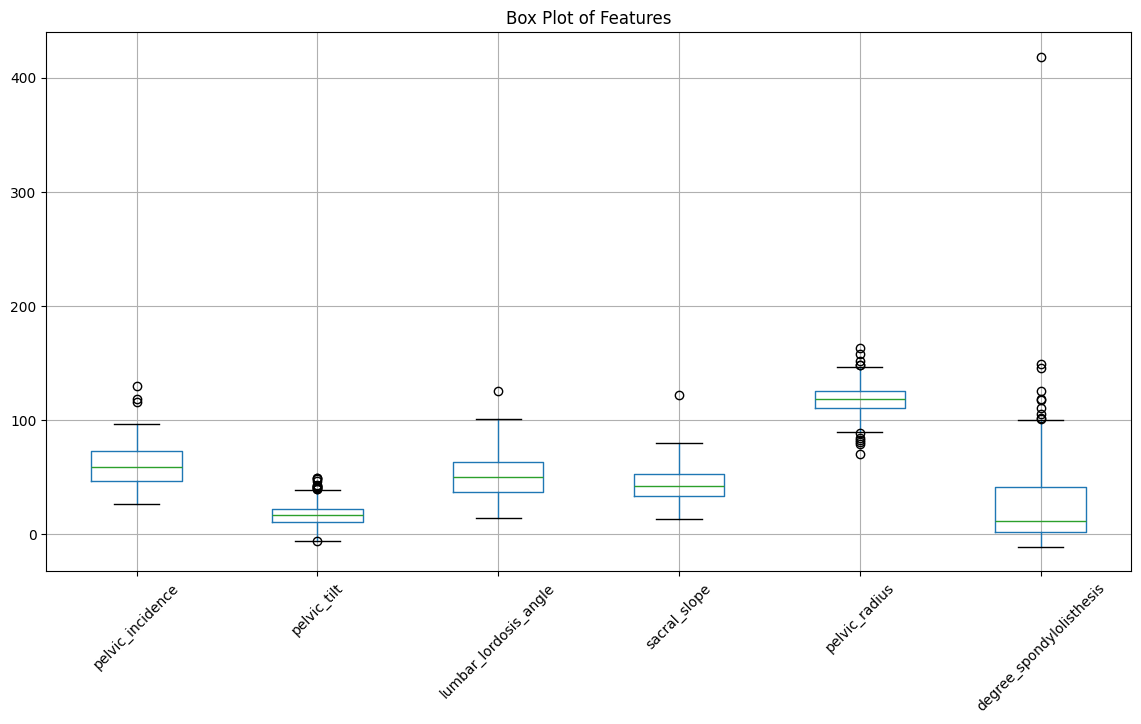

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

X.boxplot()

plt.title("Box Plot of Features")
plt.xticks(rotation=45)
plt.show()

In [11]:
for column in X.columns:

    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = X[
        (X[column] < lower) |
        (X[column] > upper)
    ]

    print(
        column,
        "->",
        len(outliers),
        "outliers"
    )

pelvic_incidence -> 3 outliers
pelvic_tilt -> 13 outliers
lumbar_lordosis_angle -> 1 outliers
sacral_slope -> 1 outliers
pelvic_radius -> 11 outliers
degree_spondylolisthesis -> 10 outliers


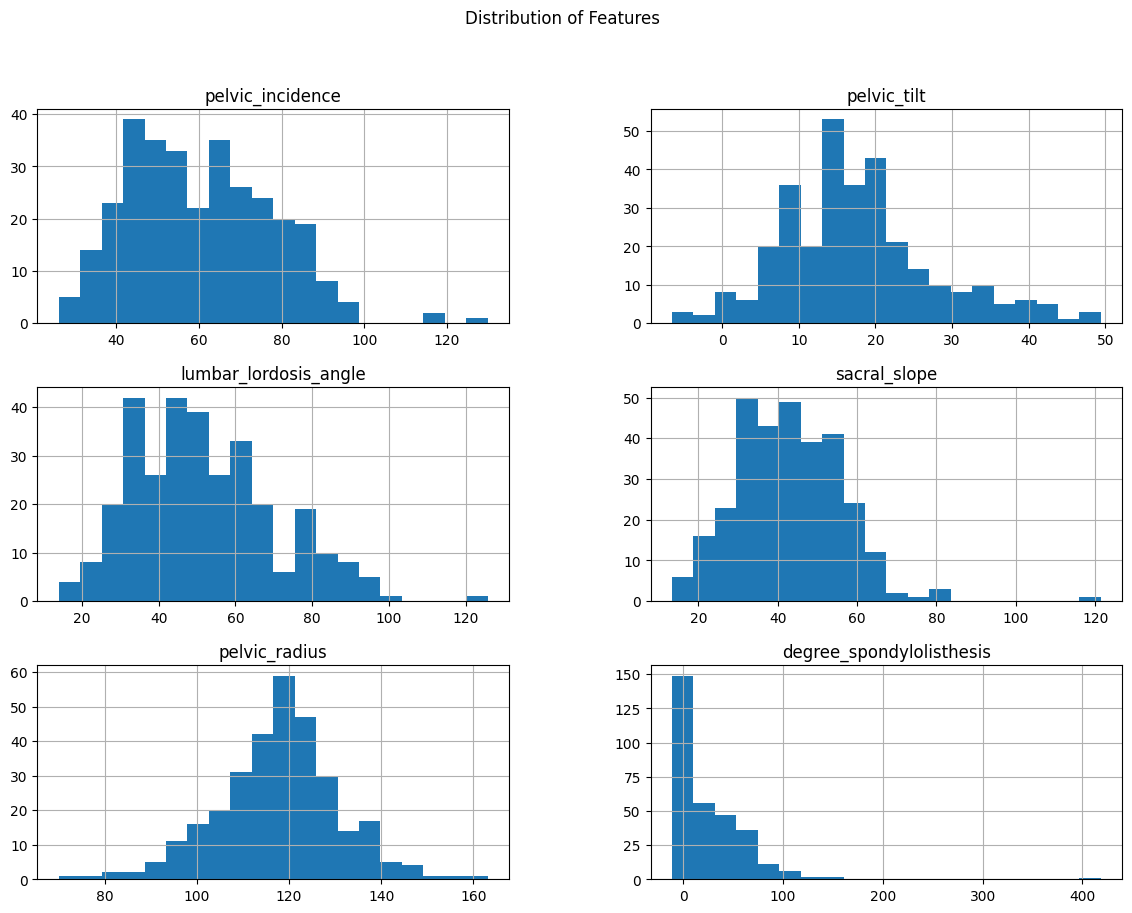

In [12]:
X.hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle("Distribution of Features")
plt.show()

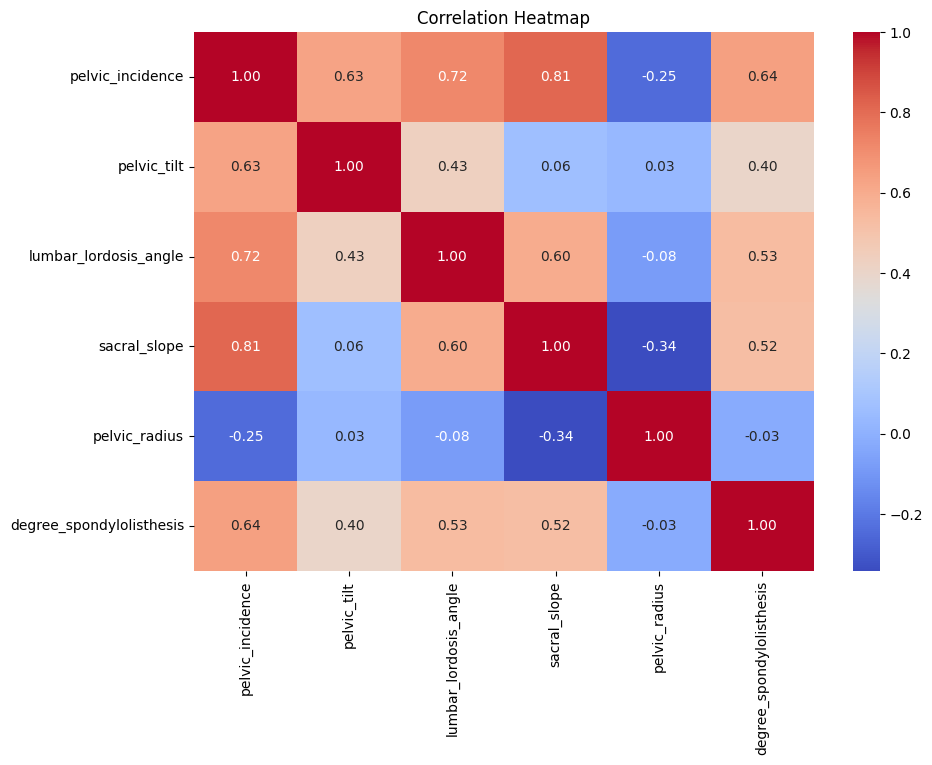

In [16]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [17]:
print(y.iloc[:, 0].value_counts())

class
Spondylolisthesis    150
Normal               100
Hernia                60
Name: count, dtype: int64


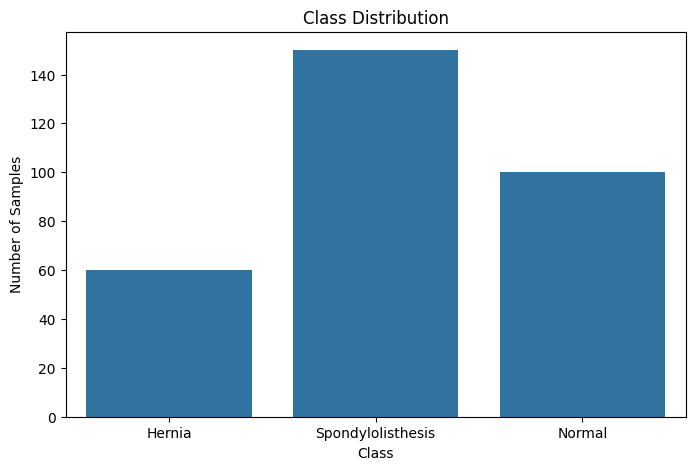

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x=y.iloc[:, 0]
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")

plt.show()

In [19]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_encoded = encoder.fit_transform(
    y.iloc[:, 0]
)

print("Original classes:")
print(encoder.classes_)

print("\nEncoded classes:")
print(np.unique(y_encoded))

Original classes:
['Hernia' 'Normal' 'Spondylolisthesis']

Encoded classes:
[0 1 2]


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (248, 6)
Testing data: (62, 6)


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

models = {

    "Logistic Regression":
        LogisticRegression(max_iter=1000),

    "KNN":
        KNeighborsClassifier(n_neighbors=5),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=200,
            random_state=42
        ),

    "SVM":
        SVC(
            probability=True,
            random_state=42
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        )
}

In [23]:
for name, model in models.items():

    model.fit(
        X_train_scaled,
        y_train
    )

    print(name, "trained successfully")

Logistic Regression trained successfully
KNN trained successfully
Random Forest trained successfully
SVM trained successfully
Decision Tree trained successfully


In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = []

for name, model in models.items():

    y_pred = model.predict(X_test_scaled)

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="macro"
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro"
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])

    print("\n", "="*50)
    print(name)
    print("="*50)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=encoder.classes_
        )
    )


Logistic Regression
                   precision    recall  f1-score   support

           Hernia       0.70      0.58      0.64        12
           Normal       0.74      0.85      0.79        20
Spondylolisthesis       0.97      0.93      0.95        30

         accuracy                           0.84        62
        macro avg       0.80      0.79      0.79        62
     weighted avg       0.84      0.84      0.84        62


KNN
                   precision    recall  f1-score   support

           Hernia       0.54      0.58      0.56        12
           Normal       0.56      0.75      0.64        20
Spondylolisthesis       1.00      0.73      0.85        30

         accuracy                           0.71        62
        macro avg       0.70      0.69      0.68        62
     weighted avg       0.77      0.71      0.72        62


Random Forest
                   precision    recall  f1-score   support

           Hernia       0.69      0.75      0.72        12
        

In [25]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8387,0.8015,0.7889,0.7921
1,KNN,0.7097,0.6980,0.6889,0.6815
2,Random Forest,0.8387,0.8074,0.8056,0.8041
3,SVM,0.8065,0.7856,0.7778,0.7784
4,Decision Tree,0.6935,0.6358,0.6389,0.6232


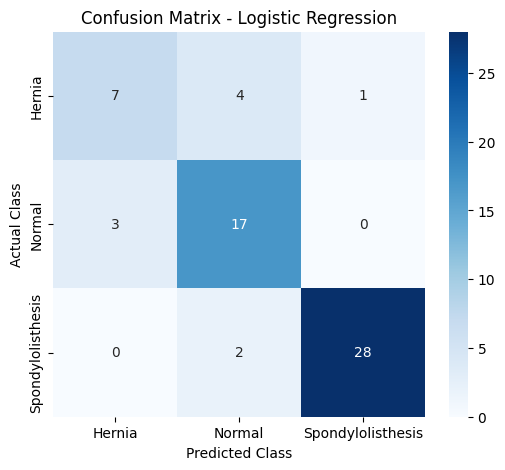

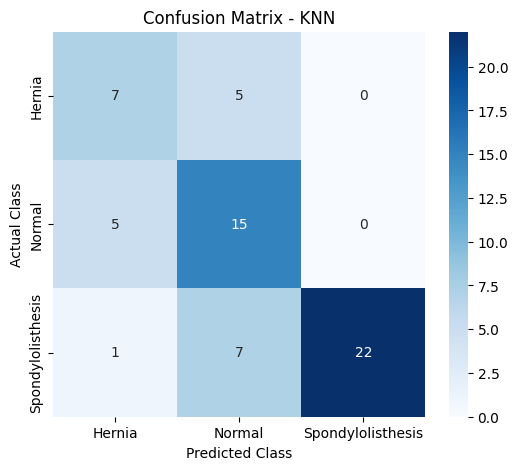

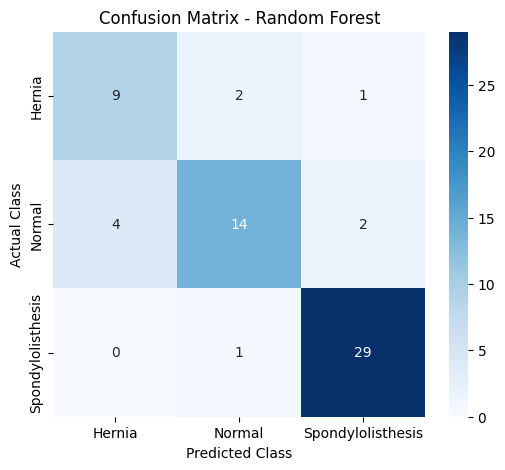

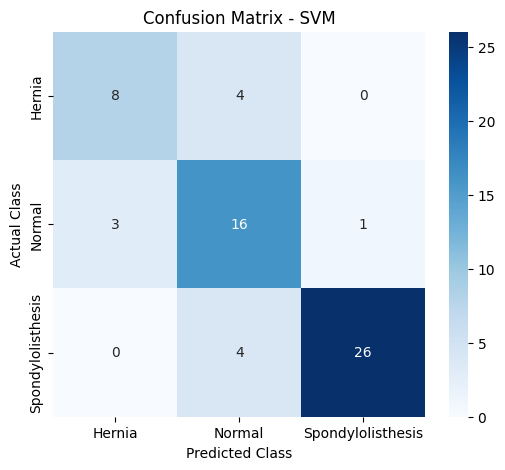

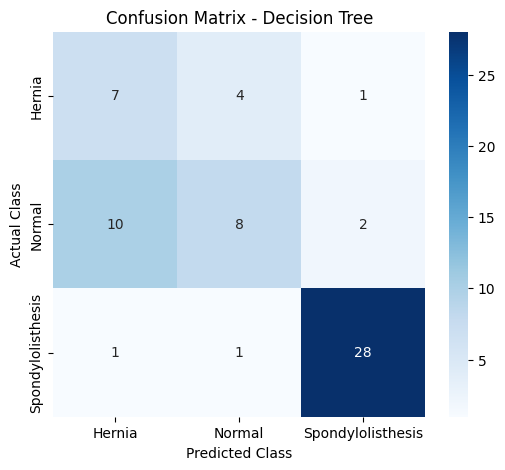

In [26]:
from sklearn.metrics import confusion_matrix

for name, model in models.items():

    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=encoder.classes_,
        yticklabels=encoder.classes_
    )

    plt.title(
        "Confusion Matrix - " + name
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.show()

In [27]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

n_classes = len(encoder.classes_)

y_test_binary = label_binarize(
    y_test,
    classes=np.arange(n_classes)
)

In [28]:
auc_results = []

for name, model in models.items():

    y_probability = model.predict_proba(
        X_test_scaled
    )

    auc_score = roc_auc_score(
        y_test_binary,
        y_probability,
        multi_class="ovr",
        average="macro"
    )

    auc_results.append([
        name,
        auc_score
    ])

    print(
        name,
        "ROC-AUC:",
        round(auc_score, 4)
    )

Logistic Regression ROC-AUC: 0.949
KNN ROC-AUC: 0.8581
Random Forest ROC-AUC: 0.9486
SVM ROC-AUC: 0.9402
Decision Tree ROC-AUC: 0.7473


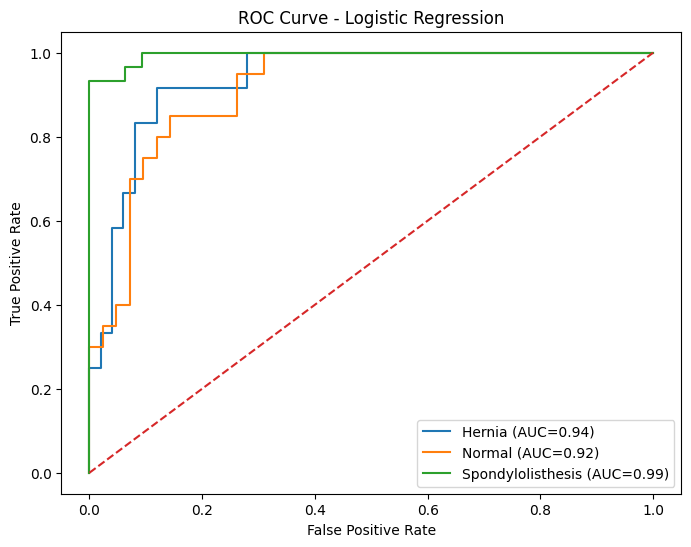

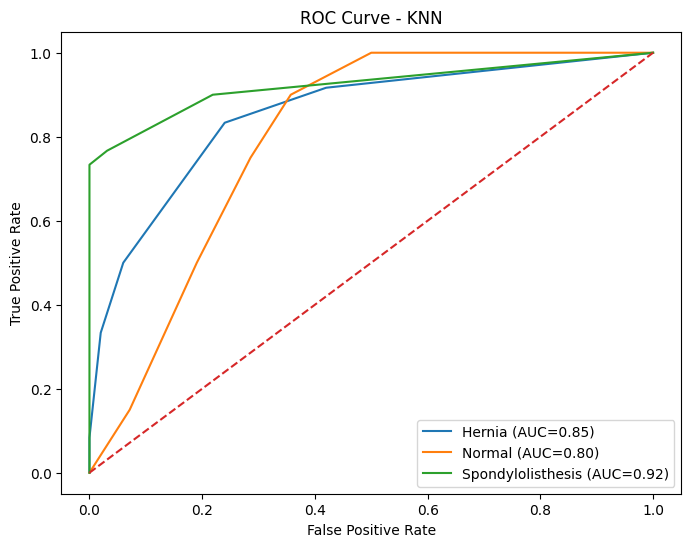

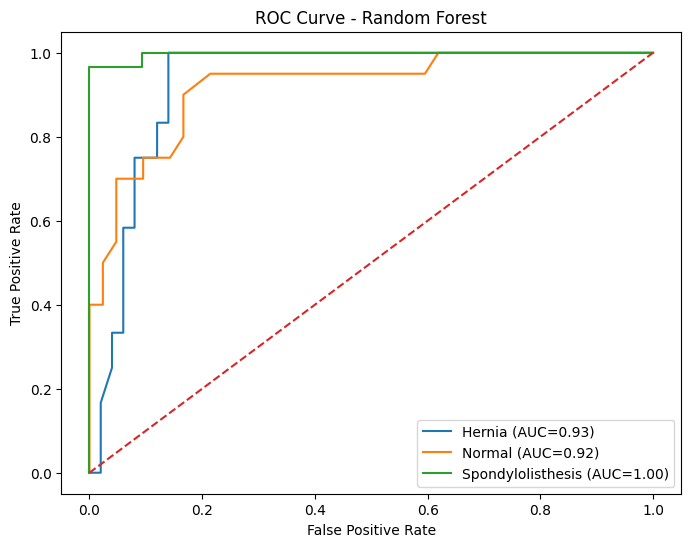

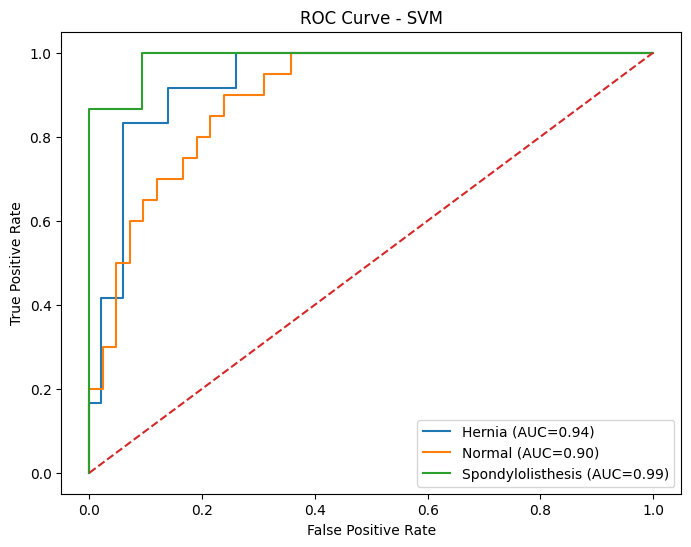

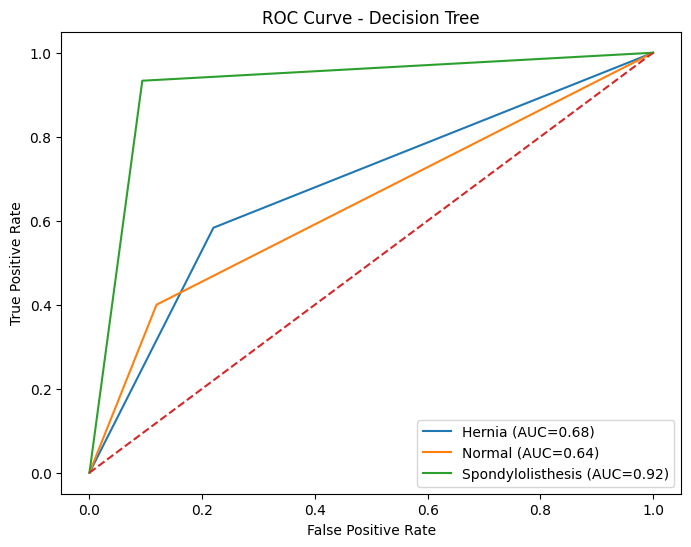

In [29]:
from sklearn.metrics import roc_curve, auc

for name, model in models.items():

    y_probability = model.predict_proba(
        X_test_scaled
    )

    plt.figure(figsize=(8, 6))

    for i in range(n_classes):

        fpr, tpr, _ = roc_curve(
            y_test_binary[:, i],
            y_probability[:, i]
        )

        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            label=f"{encoder.classes_[i]} (AUC={roc_auc:.2f})"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        "--"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.title(
        "ROC Curve - " + name
    )

    plt.legend()
    plt.show()

In [30]:
auc_df = pd.DataFrame(
    auc_results,
    columns=[
        "Model",
        "ROC-AUC"
    ]
)

final_results = results_df.merge(
    auc_df,
    on="Model"
)

final_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8387,0.8015,0.7889,0.7921,0.9490
1,KNN,0.7097,0.6980,0.6889,0.6815,0.8581
2,Random Forest,0.8387,0.8074,0.8056,0.8041,0.9486
3,SVM,0.8065,0.7856,0.7778,0.7784,0.9402
4,Decision Tree,0.6935,0.6358,0.6389,0.6232,0.7473
